<a href="https://colab.research.google.com/github/nkordylewicz/ML-for-space-applications/blob/main/algebra_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [90]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [91]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix).

***What will happen if its not gray-scale?***

> If the image is not gray-scale, it'll be converted into gray-scale using `img.convert('L')`.

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [92]:
img = Image.open("/content/drive/MyDrive/IMG_3039.jpg")
imggray = img.convert('L')

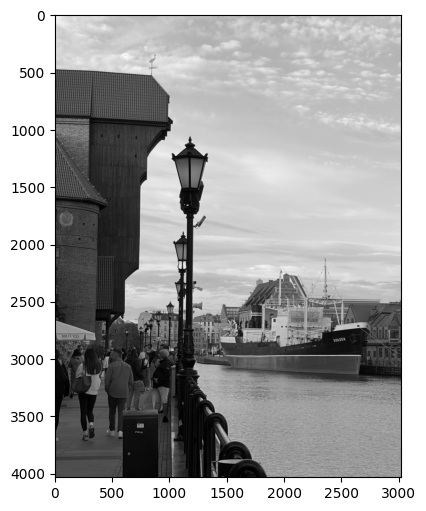

In [93]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

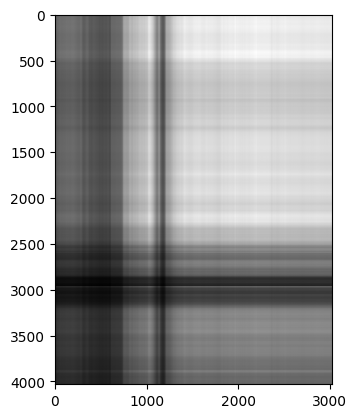

In [94]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

**What do you observe?**
> The sigma plot declines very rapidly. Highest value is above 500 000, but after a few values it's already almost 0. So in the image the information is concentrated only in several first components, and not spread evenly. The rest only adds small details.

**How many vecotrs can we use to get a decent reconstruction of the image?**
>At values around 70 the picture already looks good, but a bit like a vintage postcard. The differences are mostly visible on the people at the pathway - at 70-90 components they still lack details. Above 100-110 the reconstruction looks really good, and around 150 I would say that it's practically perfect.
**So, for a decent reconstruction, about 100 components are enough.**

**What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?**
>For better comparison, I plotted both versions. For both versions the image is still recognisable. However, the overall brightness and contrast change and the vertical stripes appear. This shows that the first components mostly carry the overall brightness of the image, while the details are stored in the following ones.

(4032, 4032) (3024,) (3024, 3024)


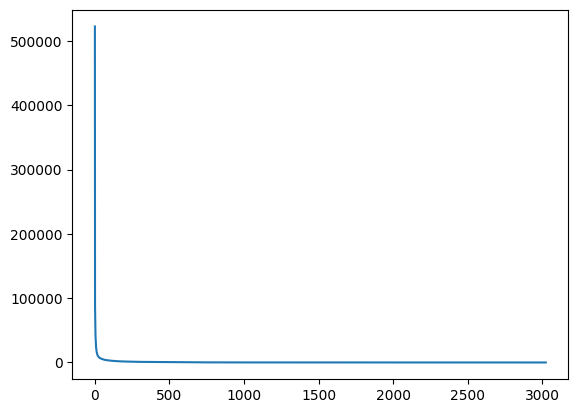

In [95]:
U.shape
sigma.shape
plt.plot(sigma)
print(U.shape, sigma.shape, V.shape)

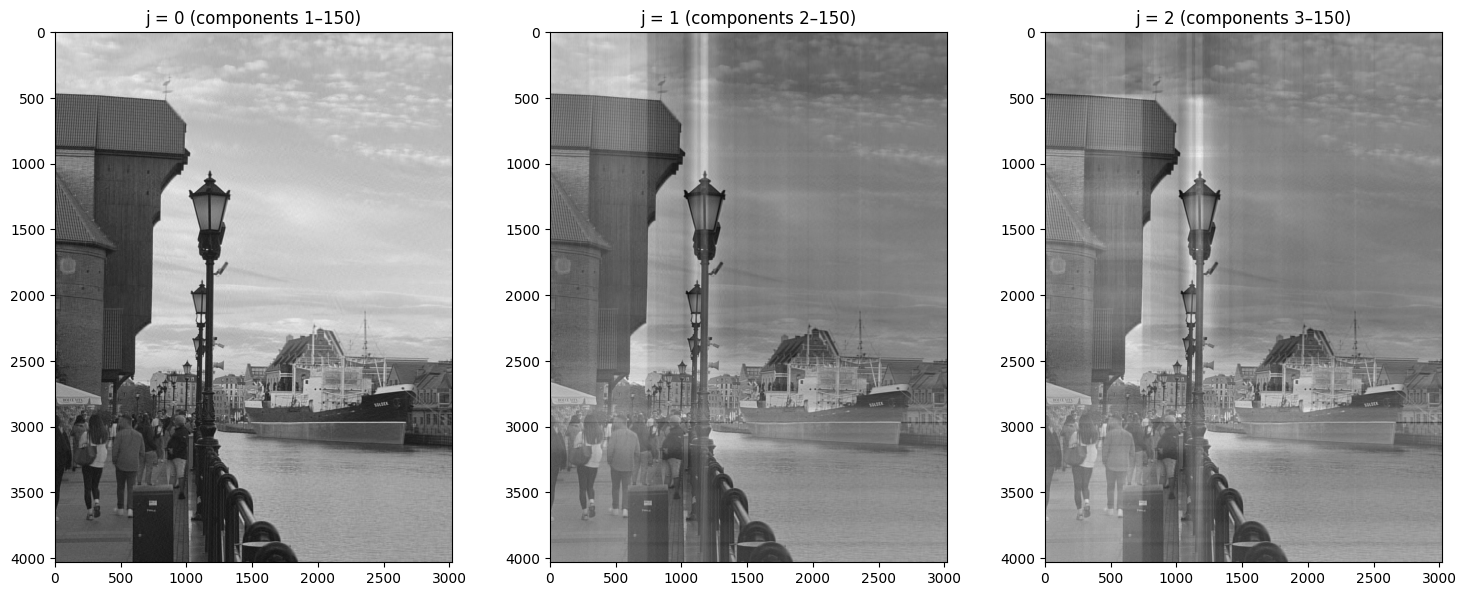

In [96]:
i = 150
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

for ax, j in zip(axes, [0, 1, 2]):
    reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
    ax.imshow(reconstimg, cmap='gray')
    ax.set_title(f"j = {j} (components {j+1}–{i})")

plt.tight_layout()
plt.show()

# Satellite Image

I loaded a satellite image from one of the labs from previous semester.

In [97]:
import tifffile as tiff

sat = tiff.imread("/content/drive/MyDrive/LANDSAT_composite_2021_to_2023.tif")
print("shape:", sat.shape, "| dtype:", sat.dtype)
print("min:", np.nanmin(sat), "| max:", np.nanmax(sat))

shape: (1979, 2829, 6) | dtype: int16
min: -95 | max: 5640


In [98]:
if sat.ndim == 3 and sat.shape[0] < sat.shape[-1]:
    sat = np.moveaxis(sat, 0, -1)

BAND = 0  # which band to use
band = sat[:, :, BAND] if sat.ndim == 3 else sat
band = np.nan_to_num(band.astype(float))

# contrast stretch
lo, hi = np.percentile(band, (2, 98))
satmat = np.clip((band - lo) / (hi - lo), 0, 1) * 255

print(satmat.shape)

(1979, 2829)


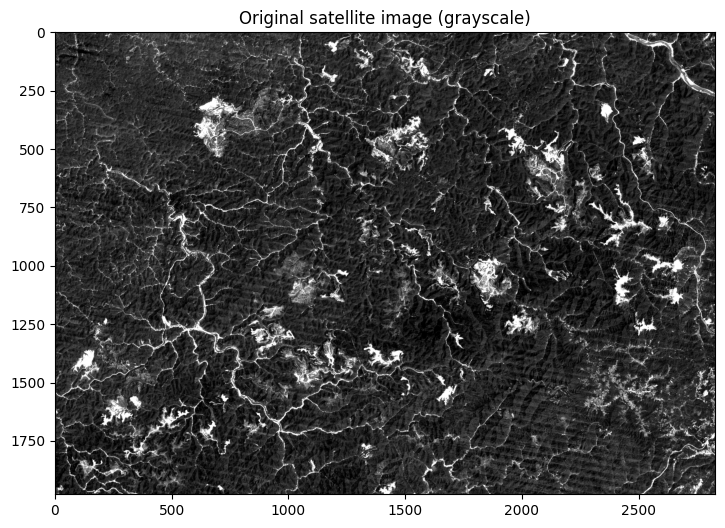

In [99]:
plt.figure(figsize=(9, 6))
plt.imshow(satmat, cmap='gray')
plt.title("Original satellite image (grayscale)")
plt.show()

In [100]:
# Task 1: SVD of the satellite image
U_s, sigma_s, V_s = np.linalg.svd(satmat, full_matrices=False)
print(U_s.shape, sigma_s.shape, V_s.shape)

(1979, 1979) (1979,) (1979, 2829)


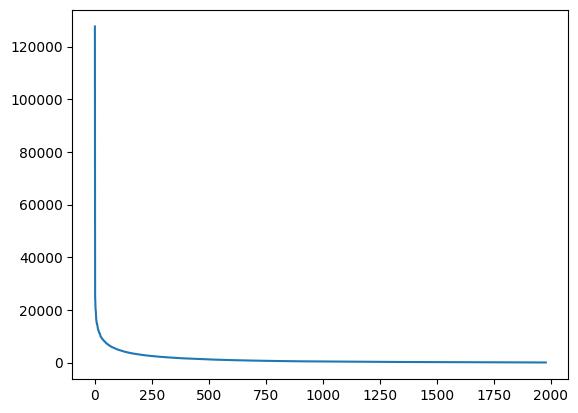

In [101]:
plt.plot(sigma_s)

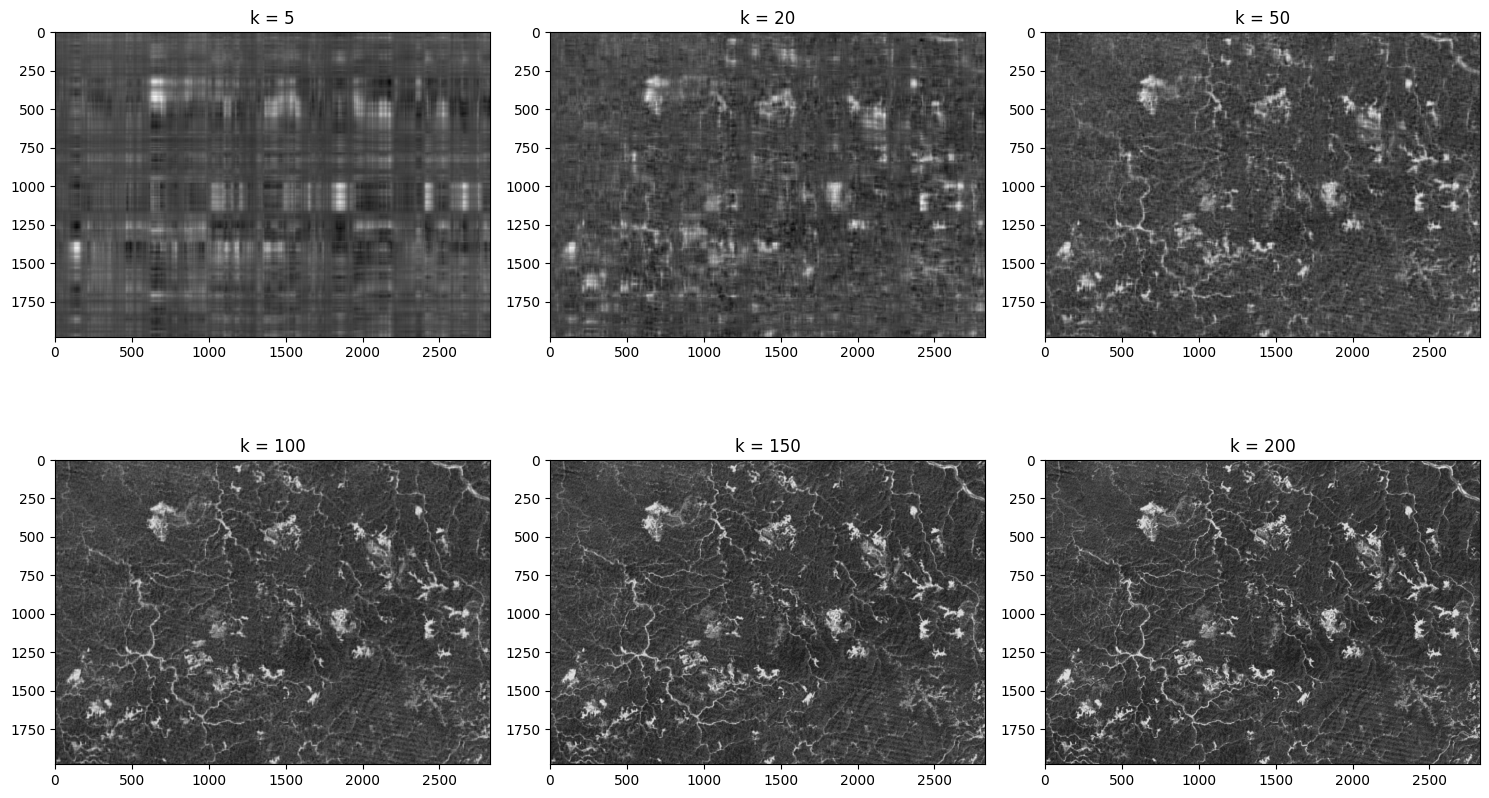

In [102]:
# Reconstruction for different numbers of components k (k plays the role of i from the example above)
ks = [5, 20, 50, 100, 150, 200]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, k in zip(axes.flat, ks):
    rec = np.matrix(U_s[:, :k]) * np.diag(sigma_s[:k]) * np.matrix(V_s[:k, :])
    ax.imshow(rec, cmap='gray')
    ax.set_title(f"k = {k}")

plt.tight_layout()
plt.show()

**How many Eigen values are good enough?**
>About 150 singular values (k = 150) are good enough. At k around 50 only some rivers are distinguishable, and at k = 100 the image looks okay, but like an image with very low resolution. At k = 150 it is hard to tell the difference from the original.

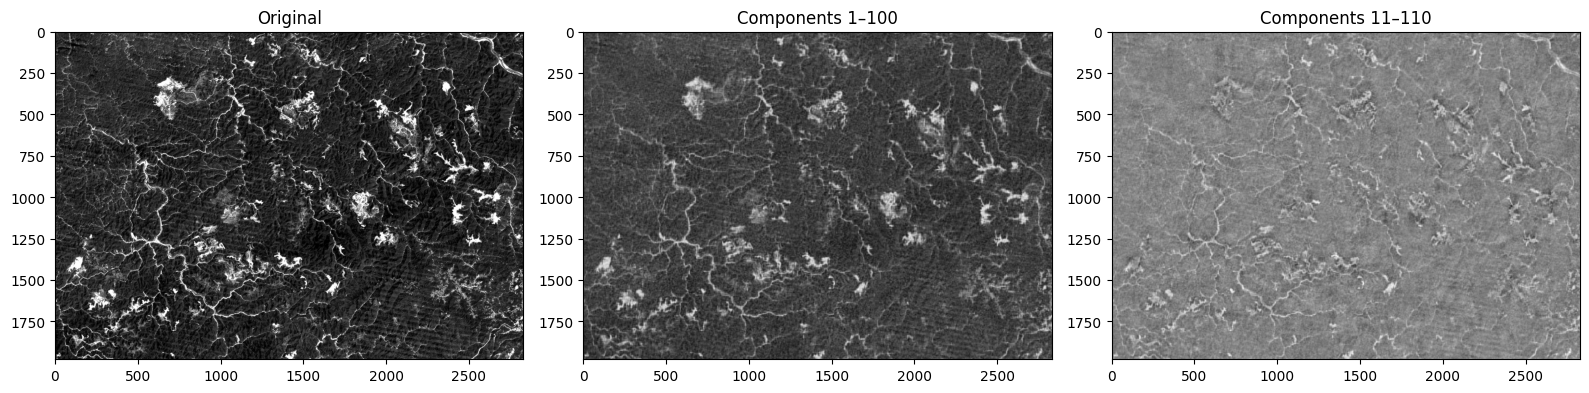

In [103]:
# Task 2
k = 100

rec_top = np.matrix(U_s[:, :k]) * np.diag(sigma_s[:k]) * np.matrix(V_s[:k, :])
rec_shift = np.matrix(U_s[:, 10:k+10]) * np.diag(sigma_s[10:k+10]) * np.matrix(V_s[10:k+10, :])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(satmat, cmap='gray')
axes[0].set_title("Original")
axes[1].imshow(rec_top, cmap='gray')
axes[1].set_title(f"Components 1–{k}")
axes[2].imshow(rec_shift, cmap='gray')
axes[2].set_title(f"Components 11–{k+10}")
plt.tight_layout()
plt.show()

**Instead of using the largest $k$ Eigen values, if you use 10th, 11th,,,,k+10 engine values, would you get better images?**
 >No. With the same number of components, the shifted version looks much worse than the one using the largest values. The image becomes grey and flat – most of the contrast and overall brightness is lost.

# Satellite Images of different terrain (forest vs urban vs ocean)

In [104]:
forest = Image.open("/content/drive/MyDrive/Forests_Sentinel-2_L2A_True_color.jpg")
forestgray = forest.convert('L')
forestmat = np.array(list(forestgray.getdata(band=0)), float)
forestmat.shape = (forestgray.size[1], forestgray.size[0])
forestmat = np.matrix(forestmat)

In [105]:
urban = Image.open("/content/drive/MyDrive/Urban_Sentinel-2_L2A_True_color.jpg")
urbangray = urban.convert('L')
urbanmat = np.array(list(urbangray.getdata(band=0)), float)
urbanmat.shape = (urbangray.size[1], urbangray.size[0])
urbanmat = np.matrix(urbanmat)

In [106]:
ocean = Image.open("/content/drive/MyDrive/Ocean_Sentinel-2_L2A_True_color.jpg")
oceangray = ocean.convert('L')
oceanmat = np.array(list(oceangray.getdata(band=0)), float)
oceanmat.shape = (oceangray.size[1], oceangray.size[0])
oceanmat = np.matrix(oceanmat)

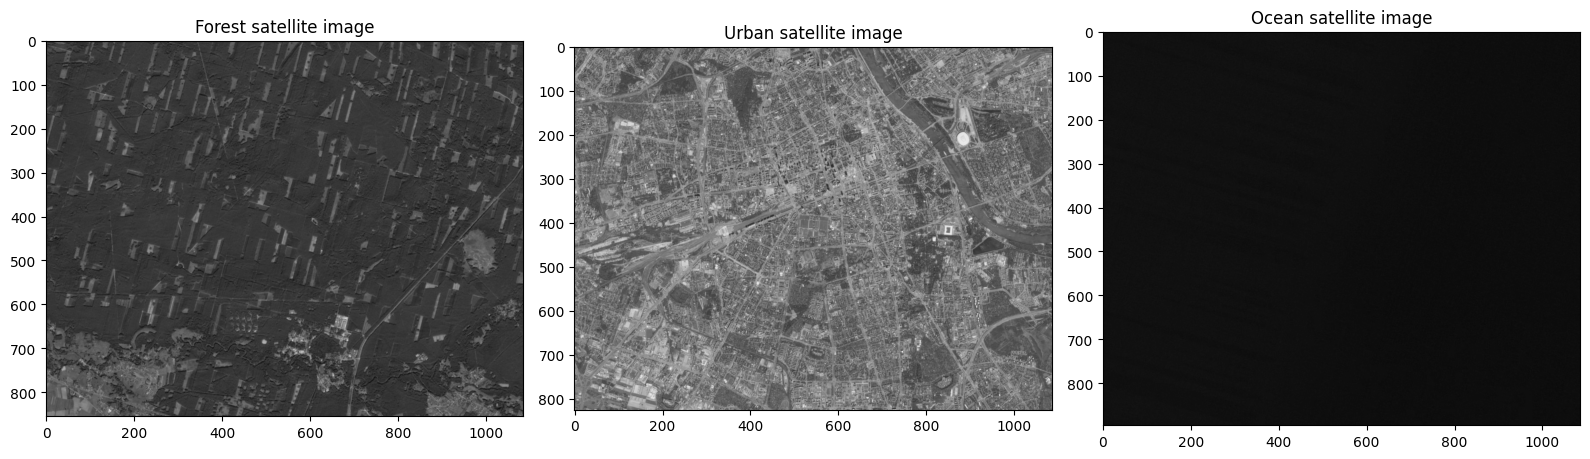

In [107]:
# Task 3
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(forestmat, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Forest satellite image")
axes[1].imshow(urbanmat, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"Urban satellite image")
axes[2].imshow(oceanmat, cmap='gray', vmin=0, vmax=255)
axes[2].set_title(f"Ocean satellite image")
plt.tight_layout()
plt.show()

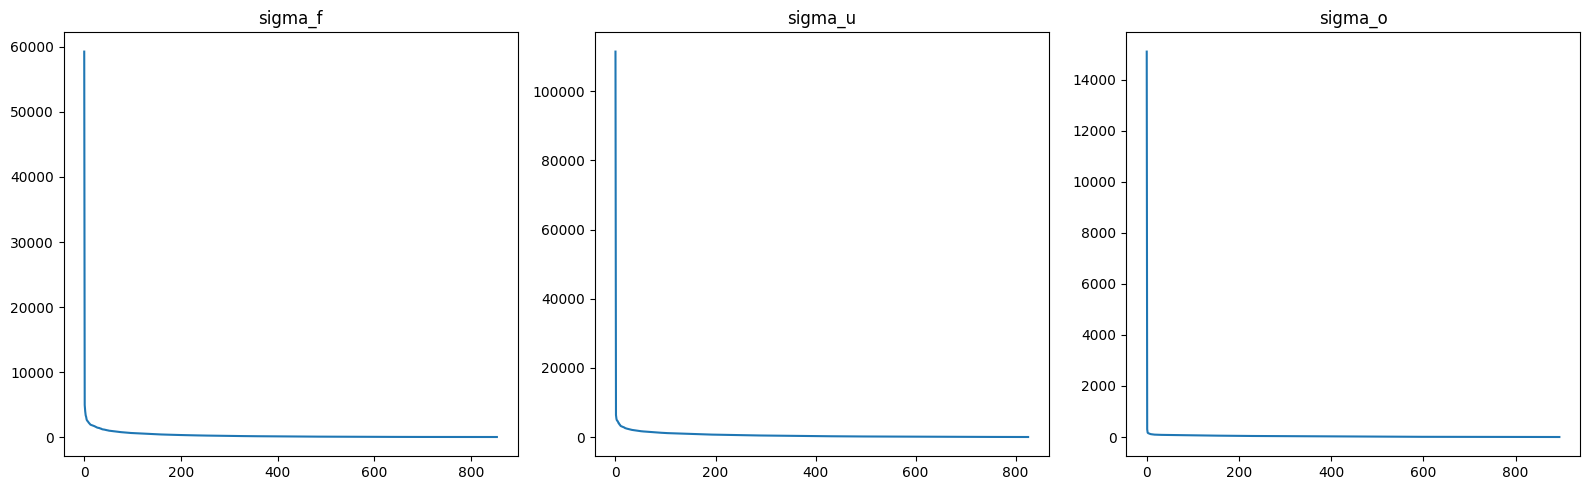

In [108]:
U_f, sigma_f, V_f = np.linalg.svd(forestmat)
U_u, sigma_u, V_u = np.linalg.svd(urbanmat)
U_o, sigma_o, V_o = np.linalg.svd(oceanmat)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].plot(sigma_f)
axes[0].set_title("sigma_f")
axes[1].plot(sigma_u)
axes[1].set_title(f"sigma_u")
axes[2].plot(sigma_o)
axes[2].set_title(f"sigma_o")
plt.tight_layout()
plt.show()

In [109]:
print(sigma_f.shape, sigma_u.shape, sigma_o.shape)

(855,) (826,) (896,)


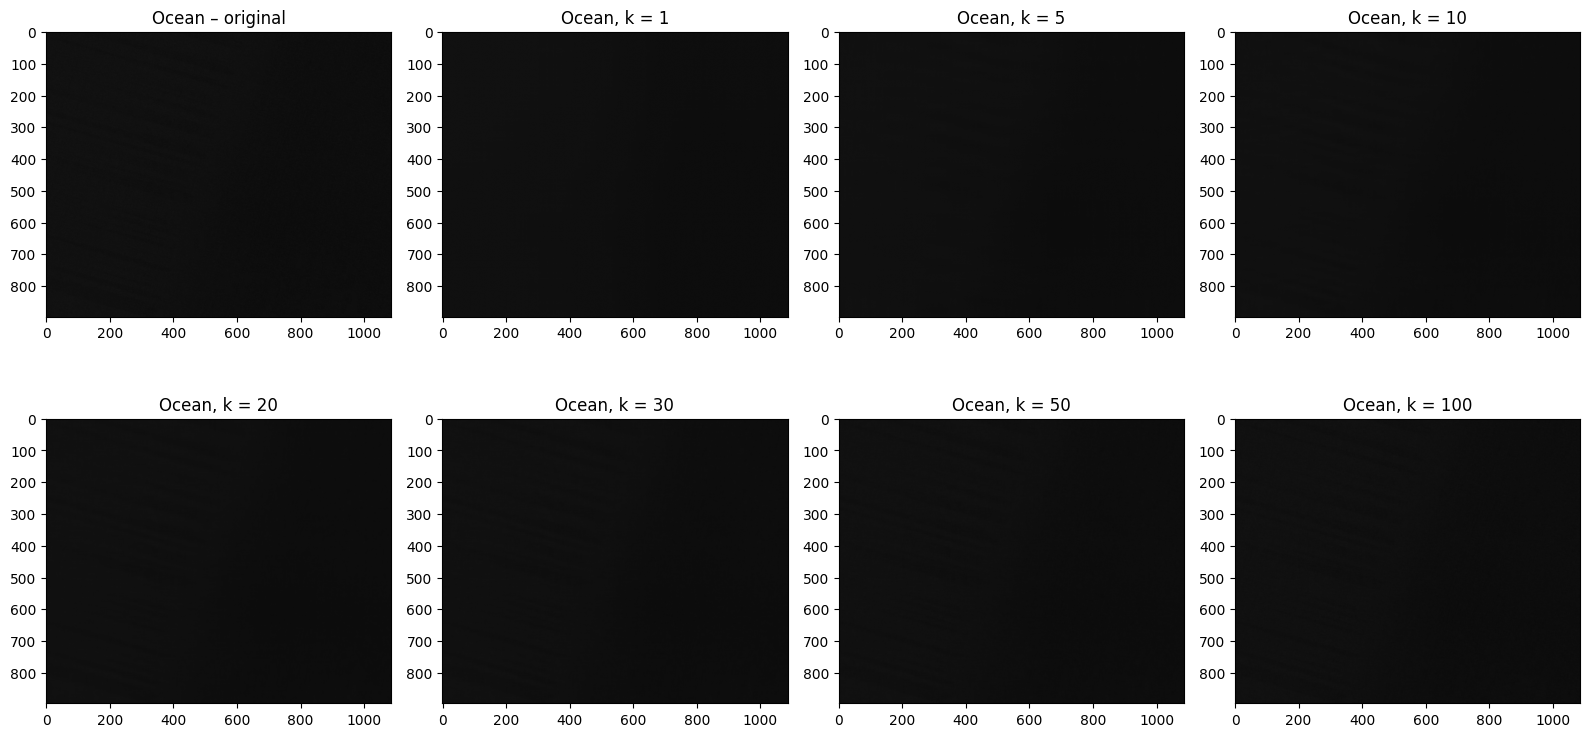

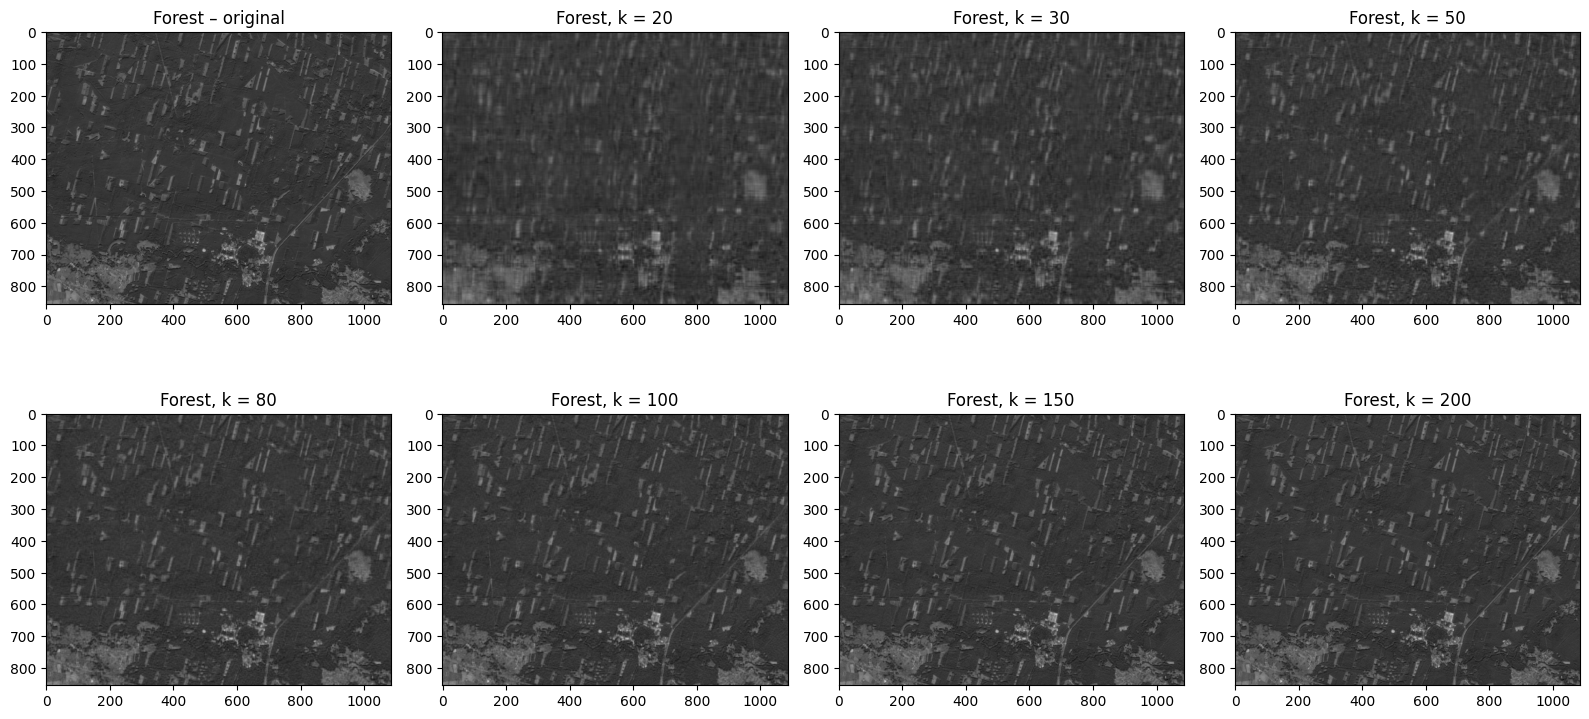

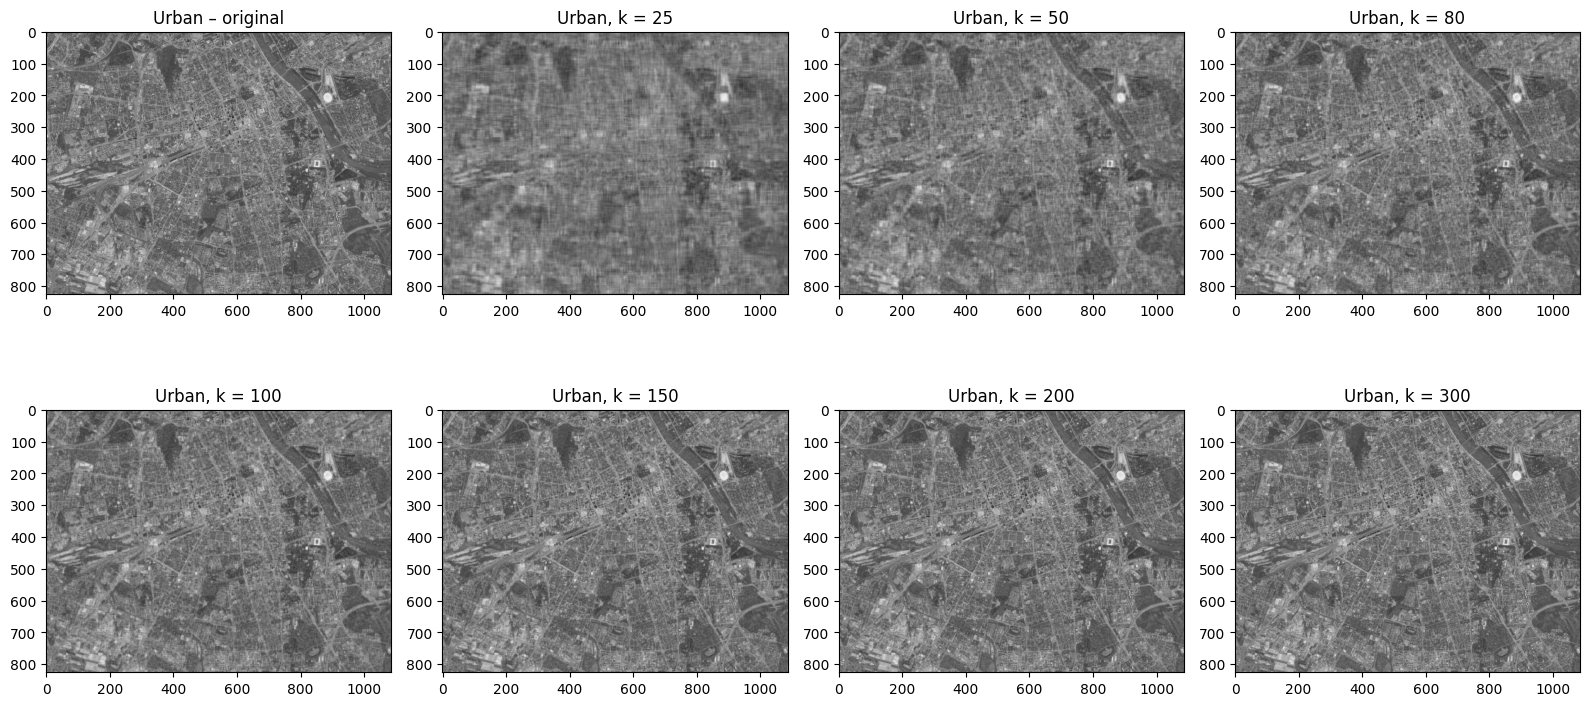

In [110]:
ks_terrain = {
    "Ocean":  [1, 5, 10, 20, 30, 50, 100],
    "Forest": [20, 30, 50, 80, 100, 150, 200],
    "Urban":  [25, 50, 80, 100, 150, 200, 300],
}
originals = {"Ocean": oceanmat, "Forest": forestmat, "Urban": urbanmat}
images = {"Ocean":  (U_o, sigma_o, V_o),
          "Forest": (U_f, sigma_f, V_f),
          "Urban":  (U_u, sigma_u, V_u)}

for name, ks in ks_terrain.items():
    U_t, sigma_t, V_t = images[name]
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flat

    axes[0].imshow(originals[name], cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(f"{name} – original")

    for ax, k in zip(axes[1:], ks):
        rec = np.matrix(U_t[:, :k]) * np.diag(sigma_t[:k]) * np.matrix(V_t[:k, :])
        ax.imshow(rec, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"{name}, k = {k}")

    plt.tight_layout()
    plt.show()

**Note how many Eigen values are enough to capture the original image without perceptual degradation.**
> - Ocean: even k = 1 looks good
> - Forest: about k = 80 – 100
> - Urban: k = 100 - 150
>
>The ocean needs the fewest components because the water surface is almost uniform – the sigma plot for the ocean drops to almost zero right after the first value. Even k = 1 is enough, because the only remaining differences are tiny changes in brightness that are not visible on a 0–255 scale.
> The forest needs more components, mostly because of the bright clear-cut
> strips and forest roads, which create many sharp edges.
> The urban area needs the most components because of many small buildings,
> streets and sharp edges spread over the whole image.
>
> This shows that the number of singular values needed depends on how much
> fine detail and how many edges the image contains.

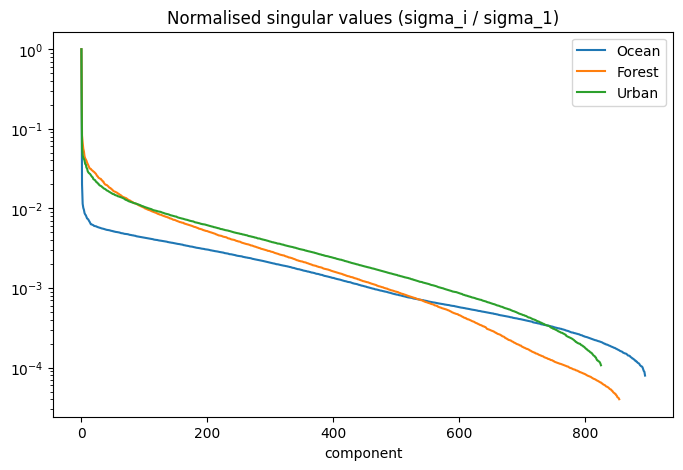

Ocean: 99% of energy at k = 1, 99.9% of energy at k = 217 (out of 896)
Forest: 99% of energy at k = 78, 99.9% of energy at k = 265 (out of 855)
Urban: 99% of energy at k = 101, 99.9% of energy at k = 338 (out of 826)


In [111]:
# Comparison of singular values for different terrains
plt.figure(figsize=(8, 5))
plt.semilogy(sigma_o / sigma_o[0], label="Ocean")
plt.semilogy(sigma_f / sigma_f[0], label="Forest")
plt.semilogy(sigma_u / sigma_u[0], label="Urban")
plt.title("Normalised singular values (sigma_i / sigma_1)")
plt.xlabel("component")
plt.legend()
plt.show()

# number of components needed to keep 99% and 99.9% of the image energy
for name, sigma_t in [("Ocean", sigma_o), ("Forest", sigma_f), ("Urban", sigma_u)]:
    energy = np.cumsum(sigma_t**2) / np.sum(sigma_t**2)
    k99 = np.argmax(energy >= 0.99) + 1
    k999 = np.argmax(energy >= 0.999) + 1
    print(f"{name}: 99% of energy at k = {k99}, 99.9% of energy at k = {k999} (out of {len(sigma_t)})")

The plot shows normalised singular values of all three terrains on one plot. The numbers show how many components are needed to keep 99% and 99.9% of the image energy.

The values agree well with the visual results: the ocean is captured almost completely by the first component, the forest needs about 80 components and the urban area about 100 or more. On the plot, the ocean curve drops the fastest at the beginning, while the urban curve stays the highest for most of the components, so the city image needs the most components.

## Conclusions
> - The singular values of an image decrease very quickly, so most of the information is stored in the first components and an image can be reconstructed well from only a small part of them (about 100 of 3024 for the photo, about 150 of 1979 for the Landsat image).
> - The first components carry the overall brightness and contrast. Removing them (Task 2) makes the image grey and flat, so using the largest k singular values always gives the best reconstruction for a given k.
> - The number of components needed depends on how much fine detail and how many sharp edges the image contains: ocean < forest < urban.

---
<sub> Note on AI use.
AI was used to explain some of the theoretical matters, polish the notebook and draft the conclusions.